# Parameter and model recovery (Appendix B.5–B.6)

We test recovery of the ten fitted parameters, their coherence-dependent differences, and the S0/S3 structure.
Fast-state innovation SD and response offsets recover more consistently than individual High readout continuity.
At the cohort level, model recovery selects S0 in 99% of S0 simulations and S3 in 91% of S3 simulations.

| | Experiment 1 | Experiment 2 |
|:--|:--|:--|
| Model | C3-S0-B2 | C3-S3-B2 |
| Free parameters | 10 | 10 |
| Generating participants | 22 | 22 |
| Independent recoveries per participant | 20 | 20 |
| Simulated data sets | 440 | 440 |
| Trials per data set | 240 | 240 |

Generating parameters come from the observed participant fits. Each simulated data set uses that participant's
actual sequence and response mask. All ten parameters are jointly refitted. Both selected C3 models fix measurement
variance at $R_H=R_L=1$; coherence modulates readout continuity and bias innovation variance.

Initial fits use 13 starting points. Fits that fail the convergence or generating-likelihood check receive
additional starts. All 880 selected fits converge and reach the generating likelihood within a tolerance of 0.01.

In [1]:
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sdu import paths as SP
from sdu.reports import recovery as P
from sdu.reports import model_recovery as E

sys.path.insert(0, str(SP.ROOT / "scripts/model"))
from parameter_recovery import OUT, PARAMETERS  # noqa: E402

P.style()
pd.set_option("display.float_format", lambda value: f"{value:.3f}")

table = pd.read_csv(OUT / "recovery_long.csv")
table = table[table.design == "fitted"].copy()
summary = pd.read_csv(OUT / "parameter_summary.csv")
summary = summary[summary.design == "fitted"].copy()
errors = pd.read_csv(OUT / "error_correlations.csv")

assert table.unit.nunique() == 880
assert table.groupby(["exp", "parameter"]).size().eq(440).all()

## 1. Parameter Recovery

*Can the ten parameters be estimated under the actual experimental design?*

**Mean r** correlates the 22 generating values with each participant's mean estimate over 20 recoveries.
**Cohort r** is the median of 20 correlations, each calculated across 22 participants using one recovery per person.
Bias and RMSE are calculated within participant over 20 recoveries, then averaged across the 22 participants.

The table compares both experiments on the fitted parameter scales. The innovation SDs
$\sigma_{q_1},\sigma_{q_2},\sigma_{q_3}$ describe the fast, slow and bias states; $\phi^L,\phi^H$ are readout
continuity; $\lambda$ is bias persistence; $d_0,\Delta d_0$ are baseline and Low–High response offsets;
$\sigma_e$ is response-noise SD; $\rho_{q_3}$ is the Low/High bias innovation variance ratio.

In [2]:
display(P.recovery_table(summary, PARAMETERS, boundary_markers=True))

† A parameter is marked when at least 20% of recoveries hit either bound in at least one experiment. For φᴴ, lower-bound rates are 46.8% in Experiment 1 and 35.7% in Experiment 2. Complete lower/upper rates are saved in `parameter_summary.csv`.

The four panels below show Low and High readout continuity. Each panel contains 440 faint single-recovery points and 22 solid participant means over 20 recoveries. The dashed line is exact recovery. Both experiments use the same scale within each row.

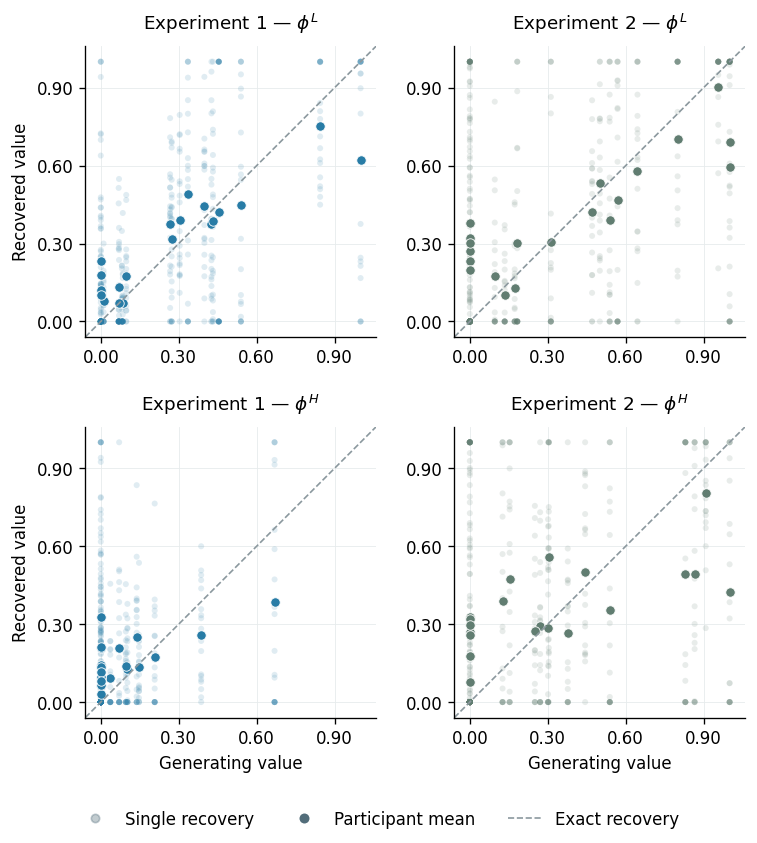

In [3]:
continuity = {name: PARAMETERS[name] for name in ("phi_L", "phi_H")}
fig = P.scatter_comparison(table, continuity)
display(fig)
plt.close(fig)

## 2. Recovery of Scientific Effects

*Can coherence-dependent retention and effective history weighting be recovered?*

We recover the Low–High continuity difference and the Low–High difference in average trace weight:

$$\Delta\phi=\phi^L-\phi^H,\qquad \Delta w=\bar w^L-\bar w^H.$$

The trial weight is $w_i=(1-K_i^{(x)})\phi_i$. We average it separately on High and Low trials over the actual
sequence. Under S3, switch trials have zero trace weight.

Rows show $\Delta\phi$ and $\Delta w$; columns show Experiments 1 and 2. The visual encoding is the same as above:
440 faint single recoveries, 22 solid participant means, and the exact-recovery diagonal. The table gives mean/cohort
correlations and group generating/recovered means outside the figure.

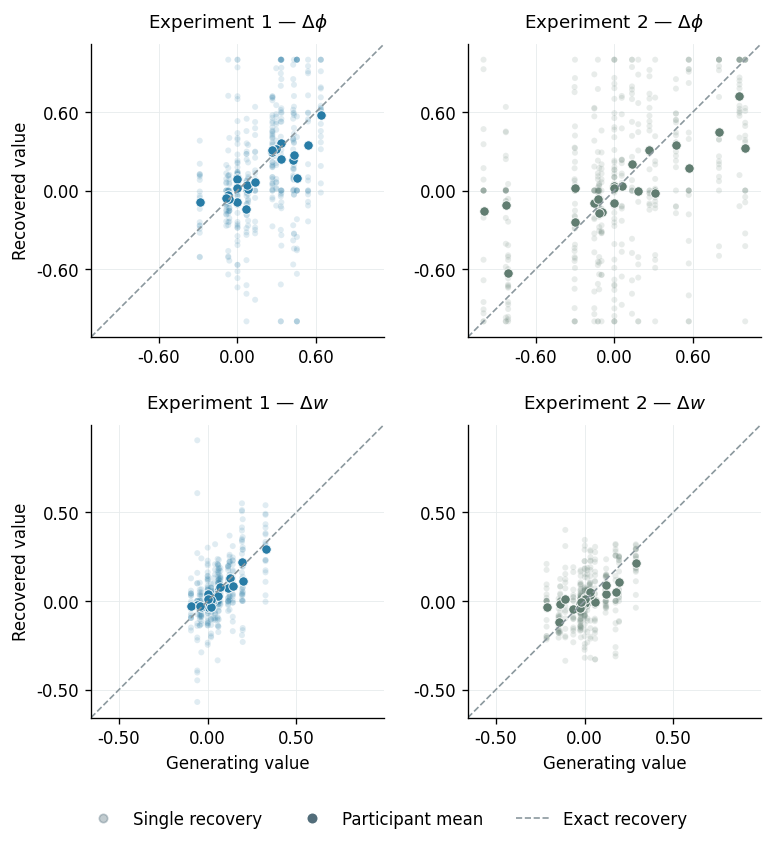

In [4]:
effects = {"delta_phi": (r"$\Delta\phi$",), "delta_weight": (r"$\Delta w$",)}
fig = P.scatter_comparison(table, effects)
display(fig)
plt.close(fig)
display(P.recovery_table(summary, effects, show_means=True))

## 3. Model Recovery

*Can S0 and S3 trace-handling mechanisms be distinguished?*

The model-recovery study uses Experiment 2 sequences. Each generating structure produces **100 simulated cohorts**,
each containing **22 simulated participants**. Every simulated participant data set is fitted with both S0 and S3,
giving 8,800 fits. Both candidates have **ten free parameters**.

Within each cohort, we average participant AIC separately for the two candidates and select the model with the
lower mean AIC. The matrix shows **cohort-level selection proportions**. S0 is selected in 99 of 100 S0 cohorts;
S3 is selected in 91 of 100 S3 cohorts.

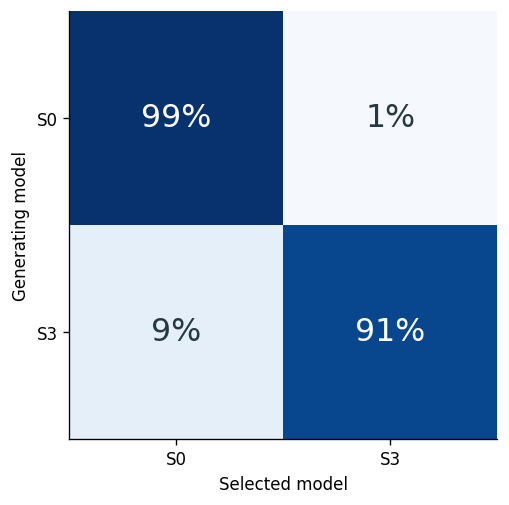

In [5]:
switch_counts = pd.read_csv(SP.MODEL_RECOVERY / "switch_confusion_counts.csv", index_col=0)
fig = E.switch_confusion(switch_counts)
display(fig)
plt.close(fig)

## 4. Additional Diagnostics

### Estimation-error correlations

Errors are centered within each generating participant across their 20 recoveries. The matrices show which
parameter estimation errors rise or fall together.

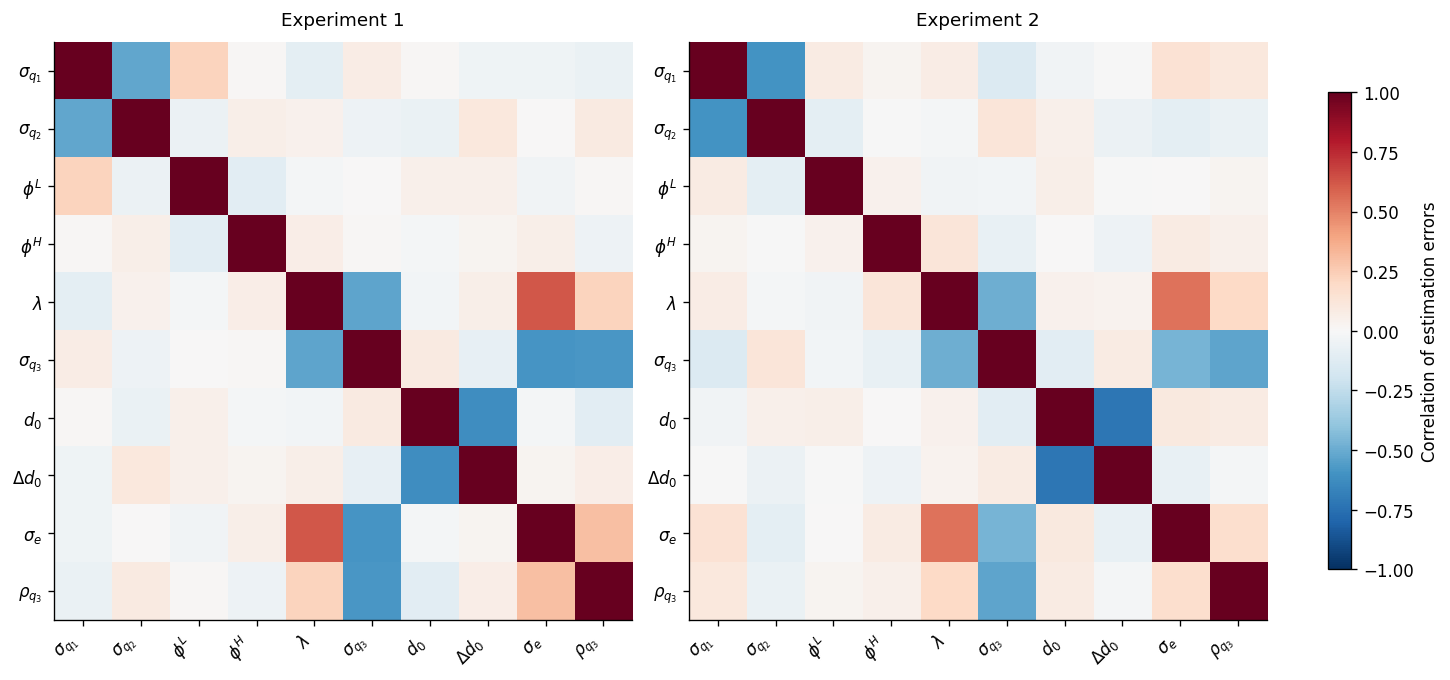

In [6]:
fig = P.error_matrix(errors, PARAMETERS)
display(fig)
plt.close(fig)

### Profile likelihood of High readout continuity

For all 44 observed participants, we fix $\phi^H$ from 0 to 1 and reoptimize the other nine parameters. Thin lines
show participant profiles; thick lines show the median. The horizontal reference is a twice-log-likelihood loss of
3.84. The figure displays losses up to 20.

The whole 0–1 grid is below the reference for **4/22 participants in Experiment 1** and **16/22 in Experiment 2**;
median supported grid spans are 0.5 and 1.0. These spans describe the likelihood profiles. In Experiment 2, the S3
reset leaves a median of 49.5 usable High trials with an active continuity path, compared with 107 in Experiment 1.
Two Experiment 2 fits have zero fast innovation SD and therefore zero fast trace.

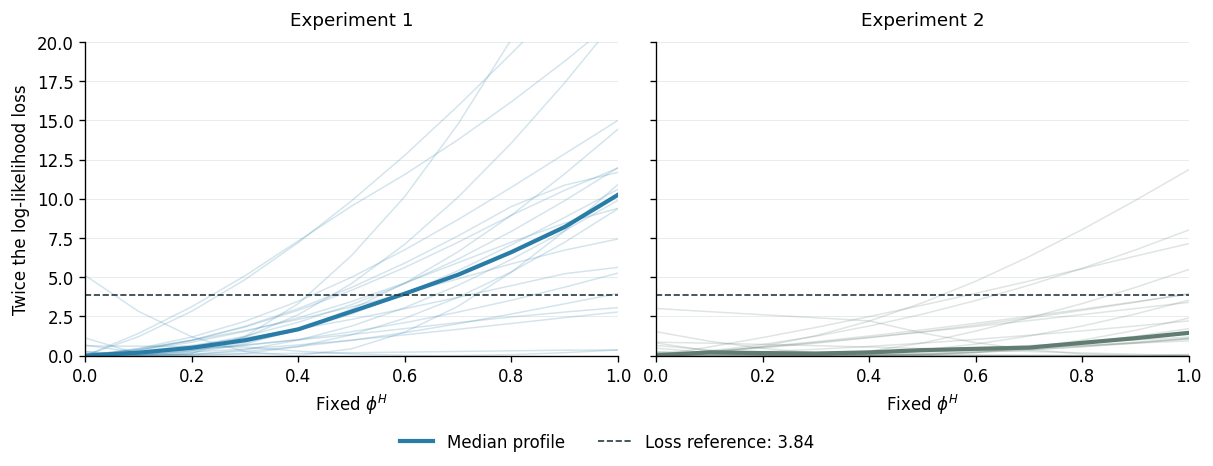

In [7]:
profiles = pd.read_csv(SP.HIGH_CONTINUITY_PROFILE / "all_curves.csv")
fig = E.phi_profiles(profiles)
display(fig)
plt.close(fig)

### Remaining parameter recovery plots

Each panel again shows 440 individual recoveries and 22 participant means. Parameter-specific axes use the fitted
units; the dashed line is exact recovery. The titles give the same mean/cohort correlations as the main table.

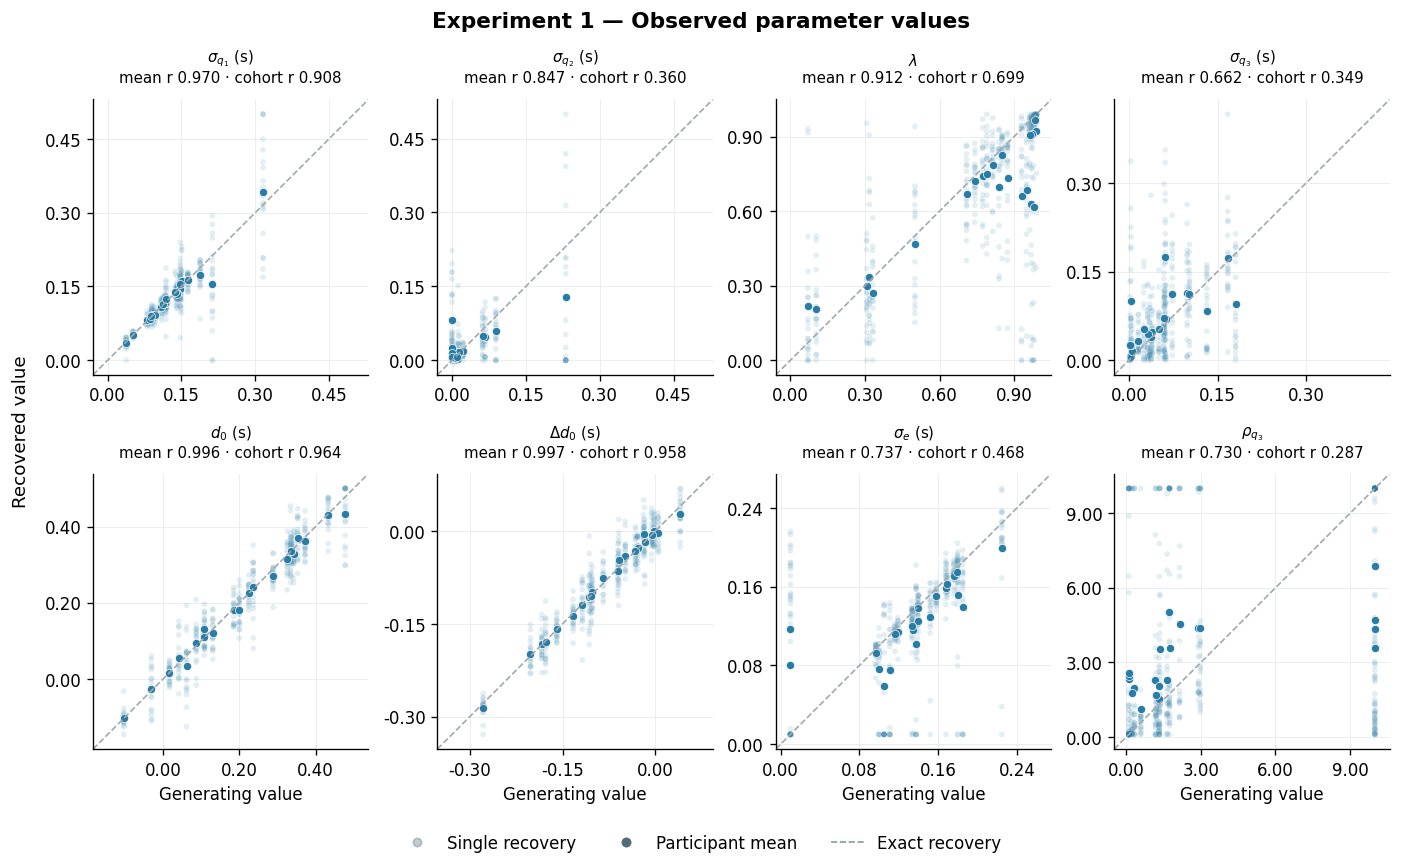

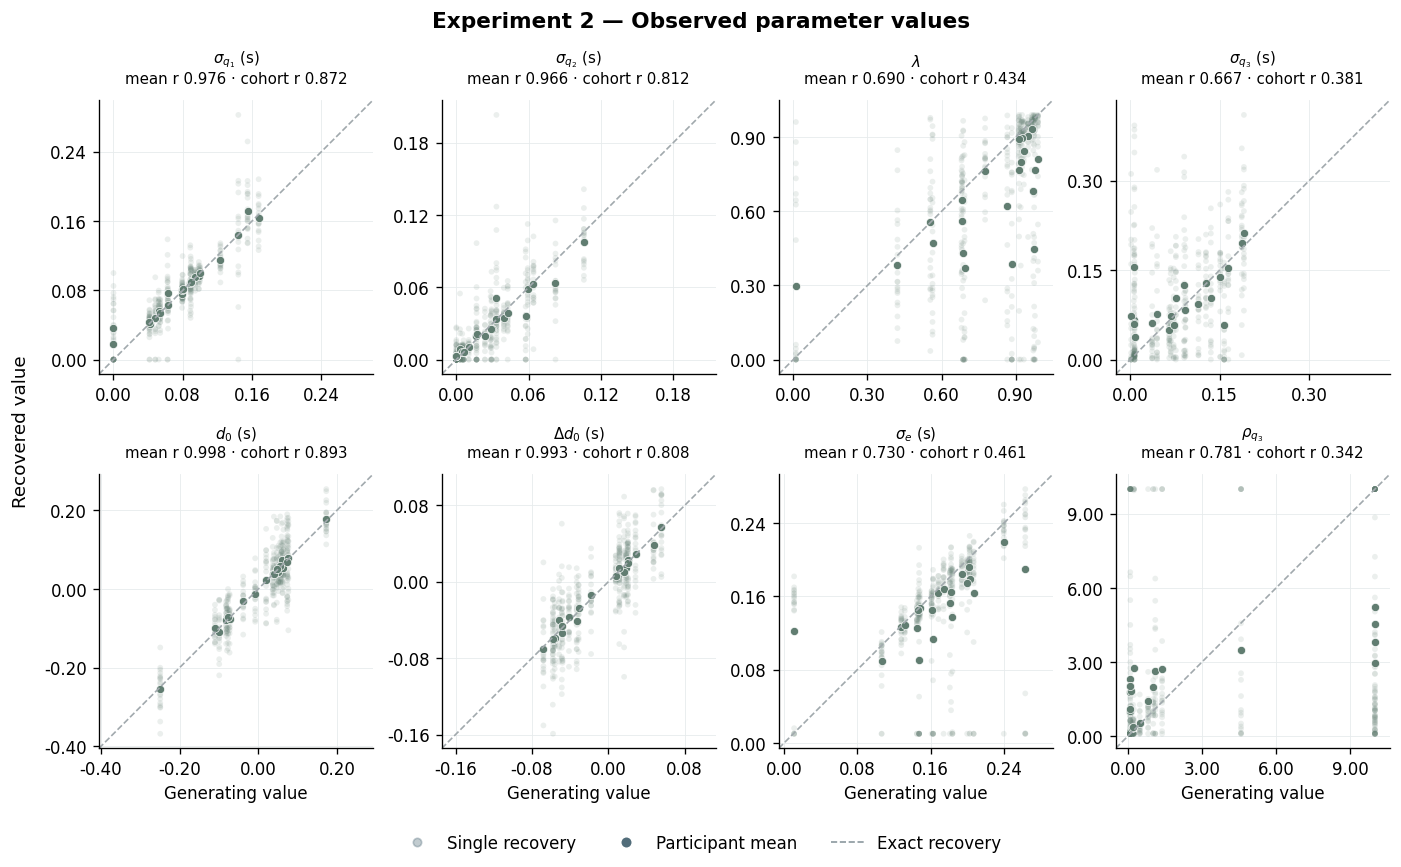

In [8]:
remaining = {name: meta for name, meta in PARAMETERS.items() if name not in continuity}
for exp in (1, 2):
    fig = P.scatter_grid(table, summary, remaining, exp, "fitted", columns=4)
    display(fig)
    plt.close(fig)

The full protocol, boundary rates, 400 exploratory parameter draws and optimizer records are saved in
`results/model/parameter_recovery/` (`scripts/model/parameter_recovery.py`, `parameter_recovery_refine.py`,
`parameter_recovery_summary.py`). The S0/S3 recovery is in `results/model/model_recovery/`
(`model_recovery.py`, `model_recovery_summary.py`) and the high-continuity profiles in
`results/model/high_continuity_profile/` (`continuity_profile.py`).